# Step 0: Data collection

### Identify patents related to quantum computing using IPC codes, CPC codes and keywords in title/abstract, alone and combined

**DOCDB patent family** (one family = one invention), as in the EPO insight report on quantum computing (January 2023).

**Recap**

1. Imports and macro variables
2. Regex handling and search concepts
3. Query functions
4. Running the queries
5. Analysis of the results
6. Semantic retrieval (BM25 vs Patent SBERT)

## 1. Imports and macro variables

In [23]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import and_, distinct, func, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,               # applications
    TLS202_APPLN_TITLE,         # titles
    TLS203_APPLN_ABSTR,         # abstracts
    TLS206_PERSON,              # persons (applicants and inventors)
    TLS207_PERS_APPLN,          # person <-> application links
    TLS209_APPLN_IPC,           # IPC classification
    TLS224_APPLN_CPC,           # CPC classification
)

In [24]:
ENV = "PROD"                        # TEST/PROD
START_YEAR, END_YEAR = 1990, 2023   # earliest filing year of the family (the EPO report starts in 1990)
IPR_TYPE = "PI"                     # patented inventions, excludes utility models
INCLUDE_BROAD = False               # also match "quantum simulation" (see section 2)
ABSTRACT_LANGUAGE = "en"
RANDOM_STATE = 42

OUTPUT_DIR = Path("outputs/step0")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)



In [25]:
patstat = PatstatClient(env=ENV)
db = patstat.orm()

patstat.list_global_tables()

## 2. Regex handling and search concepts

### 2.1 Classification codes
- **IPC**: G06N 10/00 exists only since 2019 (EPO report, Box 1), so this strategy is expected to be thin for older families.
- **CPC**: a QC subdivision exists since the creation of the CPC in 2013 (inherited from ECLA). `G06N99/002` was the place of "quantum computers" before 2019 and `Y10S977/933` is the old nanotechnology collection "spintronics or quantum computing".

Codes from neighbouring fields (`H04L9/0852` QKD, `H04B10/70` quantum communication, `B82Y10/00`, ...) are **not** used: quantum communication is a separate EPO report, and `B82Y10/00` is too broad on its own.

In [27]:
IPC_CODES = (
    "G06N10/",
    "G06N99/002",
)

CPC_CODES = (
    "G06N10/",
    "G06N99/002",
    "Y10S977/933",
)

### 2.2 Keywords as regex

`LIKE '%quantum computing%'` misses *quantum-computing*, *qu-bit*, *Shor's algorithm*, and `LIKE '%qubit%'` can not tell a word from a fragment. The keywords below are therefore written as regular expressions (PATSTAT runs on BigQuery, RE2 syntax).

- The text (title + abstract) is lower-cased before matching, so the patterns are lower-case.
- A pattern is matched as a whole word: `(^|[^a-z0-9])` before and `([^a-z0-9]|$)` after.
- No backslashes in the patterns (`[a-z0-9]` instead of `\w`), so they are safe also if the driver inlines them in the SQL string.
- `within(a, b, n)`: `a` and `b` in any order with at most `n` words in between.

The concepts follow the sub-sectors of the EPO report (general, qubits, algorithms, error correction, software/hardware). Terms that look quantum but are not quantum computing (*post-quantum* cryptography, *quantum-inspired* or *quantum-behaved* classical algorithms) are removed from the text **before** matching.

In [28]:
SEP = "[^a-z0-9]+"                   # anything between two words
QUBIT = "qu[ -]?(b|d|tr)its?"        # qubit, qu-bit, qudit, qutrit


def within(a, b, n):
    # a and b in any order, at most n words in between
    gap = f"({SEP}[a-z0-9]+){{0,{n}}}{SEP}"
    return f"({a}{gap}{b}|{b}{gap}{a})"


def word_regex(patterns):
    # whole-word match of any pattern
    return "(^|[^a-z0-9])(" + "|".join(patterns) + ")([^a-z0-9]|$)"

In [29]:
QC_PATTERNS = {
    "general": [
        "quantum[ -]+comput[a-z]*",                  # computer, computing, computation
        "quantum[ -]+information[ -]+process[a-z]*",
        "quantum[ -]+processors?",
        "quantum[ -]+processing[ -]+units?",
    ],
    "qubits_gates_circuits": [
        QUBIT,
        "quantum[ -]+bits?",
        "quantum[ -]+registers?",
        within("quantum", "(gate|circuit)s?", 1),
    ],
    "algorithms": [
        "quantum[ -]+algorithms?",
        "quantum[ -]+anneal[a-z]*",
        "quantum[ -]+optimi[sz][a-z]*",
        "quantum[ -]+machine[ -]+learning",
        "quantum[ -]+neural[ -]+network[a-z]*",
        "quantum[ -]+fourier[ -]+transform[a-z]*",
        "quantum[ -]+phase[ -]+estimation",
        "quantum[ -]+approximate[ -]+optimi[sz][a-z]*",
        "variational[ -]+quantum[ -]+(eigen[ -]?solver|algorithm|circuit)s?",
        within("quantum", "(shor|grover)'?s?", 4),
        "qaoa",
    ],
    "error_correction": [
        "quantum[ -]+error[ -]+(correct|detect|mitigat)[a-z]*",
        within("quantum", "fault[ -]+toleran[a-z]*", 3),
        within("quantum", "surface[ -]+codes?", 5),
        "stabili[sz]er[ -]+codes?",
        "magic[ -]+state[ -]+distillation",
    ],
    "software_and_hardware": [
        "quantum[ -]+(programming|software|compiler|assembler)s?",
        "(trans|flux)mons?",
        "nisq",
        "noisy[ -]+intermediate[ -]+scale[ -]+quantum",
        "qiskit",
    ],
}

# quantum simulation is a separate EPO report, so it is optional
BROAD_PATTERNS = [
    "quantum[ -]+simulat[a-z]*",
]

# removed from the text before matching
NEGATIVE_PATTERNS = [
    "post[ -]?quantum",                                          # post-quantum cryptography
    "quantum[ -]+inspired",                                      # classical algorithms
    "quantum[ -]+(behaved|behaviou?red)",                        # quantum-behaved particle swarm
    "quantum[ -]+(particle[ -]+swarm|genetic|evolutionary)",
]

# cheap LIKE prefilter: every pattern above contains one of these strings
ANCHORS = (
    "quantum", "qubit", "qu-bit", "qu bit", "qudit", "qutrit",
    "qaoa", "qiskit", "nisq", "transmon", "fluxmon",
)

patterns = [p for group in QC_PATTERNS.values() for p in group]
if INCLUDE_BROAD:
    patterns += BROAD_PATTERNS

QC_REGEX = word_regex(patterns)
NEGATIVE_REGEX = word_regex(NEGATIVE_PATTERNS)

## 3. Query functions

Same builders as in the tutorial (one per strategy, explicit joins), with two differences: every query goes through `in_scope()` (family, IP right type, time window) and returns **one row per family**.

`TEXT` is title + abstract in lower case. PATSTAT keeps one abstract per application, in the language of the document, so the English-only filter is applied later, only where it matters (section 6).

In [30]:
FAMILY_COLUMNS = (
    TLS201_APPLN.docdb_family_id,
    TLS201_APPLN.earliest_filing_year,
    TLS201_APPLN.docdb_family_size,
)

TEXT = func.lower(
    func.concat(
        func.coalesce(TLS202_APPLN_TITLE.appln_title, ""),
        " ",
        func.coalesce(TLS203_APPLN_ABSTR.appln_abstract, ""),
    )
)


def in_scope(query):
    # applications that belong to a family, of the chosen IP right type, in the time window
    return query.filter(
        TLS201_APPLN.docdb_family_id > 0,
        TLS201_APPLN.earliest_filing_year.between(START_YEAR, END_YEAR),
        TLS201_APPLN.ipr_type == IPR_TYPE,
    )


def symbol_prefix_condition(symbol_column, codes):
    # OR-condition: the blank-stripped classification symbol starts with one of the codes
    symbol = func.replace(symbol_column, " ", "")
    return or_(*(symbol.like(code.replace(" ", "") + "%") for code in codes))


def keyword_condition():
    # cheap LIKE prefilter, then the regex on the text without the false friends
    text_clean = func.regexp_replace(TEXT, NEGATIVE_REGEX, " ")
    return and_(
        or_(*(TEXT.like(f"%{a}%") for a in ANCHORS)),
        func.regexp_contains(text_clean, QC_REGEX),
    )


def query_by_keywords(*columns):
    # families with a QC keyword in the title or in the abstract
    return in_scope(
        db.query(*columns)
        .select_from(TLS201_APPLN)
        .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
        .outerjoin(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
        .filter(keyword_condition())
    )


def query_by_ipc(*columns):
    # families with at least one IPC symbol in the QC list
    return in_scope(
        db.query(*columns)
        .select_from(TLS201_APPLN)
        .join(TLS209_APPLN_IPC, TLS201_APPLN.appln_id == TLS209_APPLN_IPC.appln_id)
        .filter(symbol_prefix_condition(TLS209_APPLN_IPC.ipc_class_symbol, IPC_CODES))
    )


def query_by_cpc(*columns):
    # families with at least one CPC symbol in the QC list
    return in_scope(
        db.query(*columns)
        .select_from(TLS201_APPLN)
        .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
        .filter(symbol_prefix_condition(TLS224_APPLN_CPC.cpc_class_symbol, CPC_CODES))
    )

## 4. Running the queries

### 4.1 Query 1: IPC search

In [31]:
q_ipc = query_by_ipc(*FAMILY_COLUMNS).distinct()

df_ipc = patstat.df(q_ipc)
df_ipc.head()

,docdb_family_id,earliest_filing_year,docdb_family_size
0,78512620,2020,2
1,76796988,2020,12
2,91302201,2023,3
3,85722510,2019,6
4,90986455,2022,1


### 4.2 Query 2: CPC search

In [32]:
q_cpc = query_by_cpc(*FAMILY_COLUMNS).distinct()

df_cpc = patstat.df(q_cpc)
df_cpc.head()

,docdb_family_id,earliest_filing_year,docdb_family_size
0,82021821,2018,1
1,95155680,2023,2
2,91804396,2023,3
3,79552579,2020,5
4,80683518,2017,2


### 4.3 Query 3: keyword search

In [33]:
q_keywords = query_by_keywords(*FAMILY_COLUMNS).distinct()

df_keywords = patstat.df(q_keywords)
df_keywords.head()

,docdb_family_id,earliest_filing_year,docdb_family_size
0,36999794,2005,6
1,86483358,2022,1
2,90014249,2023,3
3,68980702,2018,23
4,66429615,2018,8


### 4.4 Query 4: hybrid

QC = keyword search **OR** IPC search **OR** CPC search. As in the tutorial, the `UNION` of the three sets of family ids is joined back to the applications to get the family attributes. The other combinations (IPC + CPC, IPC + keywords, ...) are set operations on the three results already in memory (section 5.1), no extra query is needed.

In [34]:
family_id = TLS201_APPLN.docdb_family_id.label("docdb_family_id")

hybrid_ids = (
    query_by_keywords(family_id)
    .union(query_by_ipc(family_id), query_by_cpc(family_id))
    .subquery()
)

q_hybrid = (
    db.query(*FAMILY_COLUMNS)
    .select_from(TLS201_APPLN)
    .join(hybrid_ids, TLS201_APPLN.docdb_family_id == hybrid_ids.c.docdb_family_id)
    .distinct()
)

df_hybrid = patstat.df(q_hybrid)
df_hybrid.head()

,docdb_family_id,earliest_filing_year,docdb_family_size
0,71899944,2019,3
1,75588261,2020,8
2,40252657,2007,1
3,82219067,2021,2
4,85803284,2021,3


## 5. Analysis of the results

### 5.1 How much does each strategy contribute?

Sizes of all the combinations of the three strategies, and of the seven exclusive regions of the Venn diagram.

In [35]:
ids = {
    "IPC": set(df_ipc["docdb_family_id"]),
    "CPC": set(df_cpc["docdb_family_id"]),
    "KW": set(df_keywords["docdb_family_id"]),
}

# the SQL union must be the same as the union in Python
assert set(df_hybrid["docdb_family_id"]) == set.union(*ids.values())

combos = {}
for r in (1, 2, 3):
    for names in combinations(ids, r):
        combos[" + ".join(names)] = set.union(*(ids[n] for n in names))
combos["IPC & CPC & KW (all agree)"] = set.intersection(*ids.values())

pd.Series({name: len(s) for name, s in combos.items()}, name="families")

IPC                            9035
CPC                            8567
KW                             9303
IPC + CPC                      9967
IPC + KW                      12101
CPC + KW                      11776
IPC + CPC + KW                12531
IPC & CPC & KW (all agree)     5592
Name: families, dtype: int64

In [36]:
membership = df_hybrid.set_index("docdb_family_id")
for name, s in ids.items():
    membership[name] = membership.index.isin(s)

membership.groupby(["IPC", "CPC", "KW"]).size().rename("families").reset_index()

,IPC,CPC,KW,families
0,False,False,True,2567
1,False,True,False,432
2,False,True,True,503
3,True,False,False,755
4,True,False,True,646
5,True,True,False,2043
6,True,True,True,5593


### 5.5 Precision check: read the keyword-only families

Families found **only** by the keywords are the ones with no classification to back them up. Read a random sample (title + abstract) and mark each as QC / not QC: the share of QC is a first estimate of the precision of the keyword strategy.

In [40]:
kw_only = membership[membership["KW"] & ~membership["IPC"] & ~membership["CPC"]]
sample_ids = kw_only.sample(n=min(30, len(kw_only)), random_state=RANDOM_STATE).index.tolist()

q_sample = (
    db.query(
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.appln_filing_date,
        TLS202_APPLN_TITLE.appln_title,
        TLS203_APPLN_ABSTR.appln_abstract,
    )
    .select_from(TLS201_APPLN)
    .join(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
    .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
    .filter(
        TLS201_APPLN.docdb_family_id.in_(sample_ids),
        TLS203_APPLN_ABSTR.appln_abstract_lg == ABSTRACT_LANGUAGE,
    )
)

df_sample = patstat.df(q_sample).drop_duplicates(subset=["docdb_family_id"])

pd.set_option("display.max_colwidth", 250)
df_sample

,docdb_family_id,appln_filing_date,appln_title,appln_abstract
0,55656272,2014-07-21,Anti-hacking system for quantum communication,A method and apparatus for reducing unauthorized access of an information stream. The information stream is received at a node along a path to a destination node. The information stream comprises information bits and quantum bits that are intersp...
1,71783400,2022-04-11,Superconducting optical-to-digital converter,"A system and method to convert a wideband optical signal to a multi-bit digital electrical signal using a superconducting integrated circuit. In a preferred embodiment, the optical signal modulates the phase (i.e., adjusts the timing) of a sequen..."
2,71122991,2019-01-01,Data Polarization,The Data Polarization process is completed on computer systems to make binary data information streams more efficient. The process does this by polarizing the binary segments and adding a signature to indicate how the segments were polarized for ...
3,60337454,2017-07-21,Fuel oil quantum processor and preparation method thereof,"The invention provides a fuel oil quantum processor which is prepared from rare earth alloy. The rare earth alloy is prepared from, by weight, 7.4-9.6% of Nd, 4.5-7.8% of Eu, 6.2-8.5% of Yb, 2.5-4.5% of Tb, 0.23-0.41% of Lu and the balance metal ..."
5,78150083,2020-04-15,"ALLOCATION CONTROL PROGRAM, ALLOCATION CONTROL METHOD AND INFORMATION PROCESSING DEVICE",To improve convenience of an annealing machine to which a usage upper limit is set.SOLUTION: An optimization problem arithmetic unit 201 accepts designation of the number of quantum bits and usage time corresponding to one or more specific users ...
7,40661761,2007-09-28,"QUANTUM AUTHENTICATING METHOD, QUANTUM AUTHENTICATION SYSTEM AND QUANTUM AUTHENTICATING DEVICE",<P>PROBLEM TO BE SOLVED: To perform authentication without depositing a classic password with a certificate authority. <P>SOLUTION: One quantum bit stream of a pair of quantum bits being in a first Bell state is stored in a first quantum bit hold...
8,90930194,2022-11-04,"COMBINATORIAL OPTIMIZATION DEVICE, COMBINATORIAL OPTIMIZATION CALCULATION METHOD, AND COMPUTER PROGRAM",To make a further practicable and usable delivery plan by using a quantum computer.SOLUTION: A combinatorial optimization device comprises a control unit communicably connected with a quantum computer. The control unit adds a first constraint ter...
9,67660561,2019-08-15,DISPERSIVE-RESISTIVE HYBRID ATTENUATOR FOR QUANTUM MICROWAVE CIRCUITS,A resistive component in a hybrid microwave attenuator circuit is configured to attenuate a plurality of frequencies in an input signal. The hybrid microwave attenuator circuit is further configured with a dispersive component to attenuate a seco...
10,47353554,2011-06-17,Phase qubit cell having enhanced coherence,"Methods and apparatuses are provided for storing a quantum bit. One apparatus includes a first phase qubit, a second phase qubit, and a common bias circuit configured to provide a first bias to the first phase qubit and a second bias to the secon..."
11,22427913,1999-07-29,ANALOG/DIGITAL CONVERSION METHOD AND SYSTEM,PROBLEM TO BE SOLVED: To simultaneously perform the frequency conversion of analog signals and band-pass filtering by an A/D converter provided with a voltage controlled oscillator(VCO) and a counter. SOLUTION: The analog signals including a carr...


In [41]:
# save the families, they are the input of the next steps
membership.reset_index().to_csv(OUTPUT_DIR / f"qc_families_{ENV}.csv", index=False)

# 6. Semantic retrieval: BM25 vs Patent SBERT

The classification and keyword strategies give a first QC set. Here the families of the **hybrid set** are ranked by their similarity to a textual description of quantum computing, with the two methods of the tutorial (lexical BM25, semantic Patent SBERT).

**Caution** The candidates are the output of the hybrid query, so the ranking can *sort* and *clean* the set (for example flag quantum-inspired patents that slipped in), but it can not find QC patents the three strategies missed. To measure recall, run the same code on a wider candidate set (for example every family with "quantum" in the abstract).

### 6.0 Install and import the NLP libraries

In [42]:
%pip install -q rank-bm25 sentence-transformers umap-learn

Note: you may need to restart the kernel to use updated packages.


In [43]:
import umap
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer

### 6.1 Configuration

In [44]:
SBERT_MODEL = "graziasveva93/sbert-adapt-ub"
TOP_N_DISPLAY = 5
TOP_K = 100          # keep it below the number of candidates, otherwise the top lists overlap by construction

QC_DESCRIPTION = '''
Technologies for quantum information processing and quantum computation
using quantum-mechanical properties such as superposition and entanglement.
The inventions include quantum computers and quantum processors; qubits and
quantum registers; quantum gates and quantum circuits; superconducting,
trapped-ion, neutral-atom, photonic, spin and topological qubit technologies;
quantum processor architectures and qubit control; quantum algorithms,
quantum simulation, quantum optimization and quantum machine learning;
quantum error correction, fault-tolerant quantum computing, logical qubits;
and quantum programming languages, compilers, simulators and software
platforms for programming or operating quantum computers.
'''

### 6.2 Candidates

Families of the hybrid set, represented by their earliest application with an **English abstract** (both methods need English text: in a first test the abstracts of Japanese and German applications gave unreadable tokens or off-language vectors). `has_class` tells whether the family has an IPC or CPC symbol.

In [45]:
q_candidates = (
    db.query(
        TLS201_APPLN.docdb_family_id,
        TLS201_APPLN.appln_id,
        TLS201_APPLN.appln_filing_date,
        TLS202_APPLN_TITLE.appln_title,
        TLS203_APPLN_ABSTR.appln_abstract,
    )
    .select_from(TLS201_APPLN)
    .join(hybrid_ids, TLS201_APPLN.docdb_family_id == hybrid_ids.c.docdb_family_id)
    .join(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
    .outerjoin(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
    .filter(
        TLS203_APPLN_ABSTR.appln_abstract.isnot(None),
        TLS203_APPLN_ABSTR.appln_abstract_lg == ABSTRACT_LANGUAGE,
    )
    .distinct()
)

candidates = (
    patstat.df(q_candidates)
    .dropna(subset=["appln_abstract"])
    .sort_values("appln_filing_date")
    .drop_duplicates(subset=["docdb_family_id"])   # one row per family
    .reset_index(drop=True)
)
candidates["has_class"] = candidates["docdb_family_id"].isin(ids["IPC"] | ids["CPC"])

print(f"Candidate families: {len(candidates):,}")
candidates.head()

Candidate families: 12,331


,docdb_family_id,appln_id,appln_filing_date,appln_title,appln_abstract,has_class
0,15140607,31975387,1991-06-06,COMPLIMENTARY QUANTUM EFFECT CIRCUIT,PURPOSE:To provide a complimentary quantum effect circuit contrived to reduce a power consumption. CONSTITUTION:A first AB effect element 11a having a control electrode 12a for controlling a current on the channel 11a1 on one side of channels 11a...,False
1,15860997,33294657,1991-07-09,SUPERCONDUCTING MAGNETIC FLUX QUANTUM LOGIC CIRCUIT,PURPOSE:To prevent magnetic flux from leakage over a wide range to be noise waves to the surrounding by making a clock current flow in an extremely limited center block by constituting a switching part. CONSTITUTION:A clock current (a) passes thr...,False
2,24993771,53177945,1991-08-14,Superconducting push-pull flux quantum logic circuits,Push-pull flux quantum superconducting digital logic circuits are provided with a circuit branch having a pair of Josephson junctions electrically connected in series with each other. This circuit branch is connected between positive and negative...,False
3,24993765,53177936,1991-08-14,Superconducting push-pull flux quantum gate array cells,Push-pull flux quantum gate array cells synchronously process a pair of polarized data signals. These polarized data signals can be derived from dual polarity data signals by separating the input signals into positive polarity data signals and ne...,False
4,19320202,39905528,1991-09-20,QUANTUM INTERFACE TRANSISTOR OF VERTICAL TYPE USING ELECTRON WAVE MOTION AND MANUFACTURING METHOD THEREOF,The method provides a vertical gate quantum interference transistor which has characteristics of usual FET but high operation speed and low power consumption by using electron wave property. The device includes an AlGaAs/GaAs/AlGaAs dual quantum ...,False


### 6.3 Shared helpers

Both methods give one score per abstract. The helpers turn a score into a ranking and show the top in the same format.

In [46]:
def rank_by(df, score_col):
    # copy of df sorted by score_col (descending) with a 1-based rank column
    ranked = df.sort_values(score_col, ascending=False).reset_index(drop=True)
    ranked.insert(0, "rank", np.arange(1, len(ranked) + 1))
    return ranked


def top_table(ranked, score_col, n=TOP_N_DISPLAY):
    cols = ["rank", "docdb_family_id", "appln_title", score_col, "has_class", "appln_abstract"]
    return ranked[cols].head(n)


def top_k_ids(ranked, k=TOP_K):
    return set(ranked["docdb_family_id"].head(k))

### 6.4 Method 1: BM25 (lexical)

In [47]:
TOKEN_PATTERN = re.compile(r"\b[a-zA-Z0-9]+\b")


def tokenize(text):
    return TOKEN_PATTERN.findall(text.lower())


bm25 = BM25Okapi([tokenize(text) for text in candidates["appln_abstract"].astype(str)])
candidates["bm25_score"] = bm25.get_scores(tokenize(QC_DESCRIPTION))

ranked_bm25 = rank_by(candidates, "bm25_score")
top_table(ranked_bm25, "bm25_score")

,rank,docdb_family_id,appln_title,bm25_score,has_class,appln_abstract
0,1,88791741,DIGITAL CIRCUITS FOR QUANTUM COMPUTERS IMPLEMENTATION OF QUBIT WITH CONTROLLABLE PROBABILITY OF STATES AND ALLOCATION OF ADJUSTABLE NOISE AND QUGATE WITH NOISE INJECTION,175.554275,True,"The quantum computation principle is based on the phenomenon of superposition of states exhibited in specialized cells called quantum bits or qubits. Helped by quantum gates, the qubits can be connected into circuits with architectures determined..."
1,2,88920882,QUANTUM COMPUTING SYSTEM AND METHOD FOR ERROR DETECTION,167.086623,True,"A quantum computing system and a method for quantum error detection are disclosed, for performing a quantum operation with fault tolerance provided by detectability of specific logical errors during initialisation, syndrome measurement and state ..."
2,3,96657971,QUANTUM COMPUTING SYSTEM AND METHOD FOR ERROR DETECTION,167.086623,True,"A quantum computing system and a method for quantum error detection are disclosed, for performing a quantum operation with fault tolerance provided by detectability of specific logical errors during initialisation, syndrome measurement and state ..."
3,4,84840034,Quantum computing system and method for error detection,166.912418,True,"A method of performing quantum error detection using fault tolerant operations wherein a number k of logical qubits are encoded into k+2 physical qubits 1,...k, t and b ([k+2, k, 2], quantum error correction code), wherein the quantum error detec..."
4,5,91219738,Quantum computer operating system and quantum computer,166.384908,True,"The invention discloses a quantum computer operating system and a quantum computer.The system comprises a quantum computing application module, a quantum programming framework module and a quantum computing system service module which are in comm..."


### 6.5 Method 2: Patent SBERT-adapt-ub (semantic)

In [48]:
model = SentenceTransformer(SBERT_MODEL)

abstract_embeddings = model.encode(
    candidates["appln_abstract"].astype(str).tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True,
)
qc_embedding = model.encode(QC_DESCRIPTION, convert_to_numpy=True, normalize_embeddings=True)

print("Embedding matrix:", abstract_embeddings.shape)   # (n_patents, embedding_dim)

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/4.99k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (7 outputs left out)

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/386 [00:00<?, ?it/s]

Embedding matrix: (12331, 384)


In [49]:
candidates["sbert_similarity"] = abstract_embeddings @ qc_embedding   # cosine similarity

ranked_sbert = rank_by(candidates, "sbert_similarity")
top_table(ranked_sbert, "sbert_similarity")

,rank,docdb_family_id,appln_title,sbert_similarity,has_class,appln_abstract
0,1,35943085,Quantum computational systems,0.988952,True,"Apparatus and methods for performing quantum computations are disclosed. Such quantum computational systems may include quantum computers, quantum cryptography systems, quantum information processing systems, quantum storage media, and special pu..."
1,2,82569846,Quantum computing processing method and device and electronic equipment,0.986431,True,"The invention provides a quantum computing processing method and device and electronic equipment, and relates to the technical field of quantum computing, in particular to the technical field of quantum circuits. According to the specific impleme..."
2,3,81327128,OPTIMAL CALIBRATION OF GATES IN A QUANTUM COMPUTING SYSTEM,0.985103,True,"A method of performing a quantum computation process includes mapping, by a classical computer, logical qubits to physical qubits of a quantum processor so that quantum circuits are executable using the physical qubits of the quantum processor an..."
3,4,81597848,SYMMETRY-PROTECTED QUANTUM COMPUTATION,0.983935,True,"In a quantum-computation method, quantum-computer code is received for execution on a quantum computer. The quantum computer includes a plurality of qubits associated with a corresponding plurality of particles, and the plurality of particles def..."
4,5,96173946,Privacy-Preserving Quantum Computation Using Masked Quantum Circuit,0.983836,True,"Systems and methods for quantum computation are provided. In one example, performing quantum computation using a masked circuit can include obtaining, by a classical computing system, data indicative of a quantum computation circuit. One or more ..."


### 6.6 Comparing the two rankings

In [50]:
n = TOP_N_DISPLAY
comparison_top = pd.DataFrame(
    {
        "rank": range(1, n + 1),
        "BM25 family": ranked_bm25["docdb_family_id"].head(n).values,
        "BM25 title": ranked_bm25["appln_title"].head(n).values,
        "SBERT family": ranked_sbert["docdb_family_id"].head(n).values,
        "SBERT title": ranked_sbert["appln_title"].head(n).values,
    }
)
comparison_top

,rank,BM25 family,BM25 title,SBERT family,SBERT title
0,1,88791741,DIGITAL CIRCUITS FOR QUANTUM COMPUTERS IMPLEMENTATION OF QUBIT WITH CONTROLLABLE PROBABILITY OF STATES AND ALLOCATION OF ADJUSTABLE NOISE AND QUGATE WITH NOISE INJECTION,35943085,Quantum computational systems
1,2,88920882,QUANTUM COMPUTING SYSTEM AND METHOD FOR ERROR DETECTION,82569846,Quantum computing processing method and device and electronic equipment
2,3,96657971,QUANTUM COMPUTING SYSTEM AND METHOD FOR ERROR DETECTION,81327128,OPTIMAL CALIBRATION OF GATES IN A QUANTUM COMPUTING SYSTEM
3,4,84840034,Quantum computing system and method for error detection,81597848,SYMMETRY-PROTECTED QUANTUM COMPUTATION
4,5,91219738,Quantum computer operating system and quantum computer,96173946,Privacy-Preserving Quantum Computation Using Masked Quantum Circuit


In [51]:
k = min(TOP_K, len(candidates))   # cannot take more families than there are candidates

bm25_top_ids = top_k_ids(ranked_bm25, k)
sbert_top_ids = top_k_ids(ranked_sbert, k)
overlap = bm25_top_ids & sbert_top_ids

print(f"Candidates: {len(candidates)} | top-K: {k}")
print(f"Families in both top-{k} lists: {len(overlap)} ({len(overlap) / k:.1%})")

candidates["in_bm25_top"] = candidates["docdb_family_id"].isin(bm25_top_ids)
candidates["in_sbert_top"] = candidates["docdb_family_id"].isin(sbert_top_ids)

Candidates: 12331 | top-K: 100
Families in both top-100 lists: 9 (9.0%)


What the ranking says about the strategies of section 4: do families with an IPC/CPC symbol score higher than keyword-only families? And what sits at the **bottom** of the semantic ranking? Read those titles: they are the first candidates to drop from the final QC set (or to discuss as a scope decision, for example quantum-inspired algorithms).

In [52]:
candidates.groupby("has_class")[["bm25_score", "sbert_similarity"]].median()

,bm25_score,sbert_similarity
has_class,,
False,102.580157,0.771352
True,107.036572,0.853716


In [53]:
ranked_sbert[["rank", "docdb_family_id", "appln_title", "sbert_similarity", "has_class"]].tail(10)

,rank,docdb_family_id,appln_title,sbert_similarity,has_class
12321,12322,67212932,Vibrationally isolated cryogenic shield for local high-quality vacuum,-0.085865,True
12322,12323,82931647,"Atom Beam Generation Device, Physical Package, Optical Lattice Clock Physical Package, Atomic Clock Physical Package, Atomic Interferometer Physical Package, Quantum Information Processing Device Physical Package, and Physical Package System",-0.091978,False
12323,12324,77465817,Low temperature low-abundance atomic object dispenser,-0.092673,True
12324,12325,82022356,FOLDABLE DOLL WITH PROJECTION FUNCTION,-0.108794,True
12325,12326,67444622,Automatic bait casting device for mudflat aquaculture,-0.118643,False
12326,12327,90542467,"Pre-cooling device, refrigeration equipment and quantum computer",-0.126211,False
12327,12328,93794827,COLD SERVICEABLE CRYOGENIC SYSTEM,-0.141091,True
12328,12329,84839964,Vacuum chamber and vacuum system,-0.170375,True
12329,12330,75769643,PROTECTIVE ARTICLE COMPRISING AT LEAST ONE CLAY IMPREGNATED SUPPORT,-0.212038,True
12330,12331,58016703,"PARTING MACHINE, WORKPIECE POSITIONING DEVICE",-0.388713,True


### 6.7 Visualising the semantic space with UMAP

The description is projected **together with** the abstracts (last row of the input), so it appears on the same map.

In [54]:
umap_input = np.vstack([abstract_embeddings, qc_embedding.reshape(1, -1)])

reducer = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine",
    random_state=RANDOM_STATE,
)
coords = reducer.fit_transform(umap_input)

candidates[["UMAP_1", "UMAP_2"]] = coords[:-1]   # one point per family
qc_xy = coords[-1]                               # the description

/opt/conda/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [55]:
def plot_retrieval_map(df, highlight_col, highlight_label, title, query_xy=qc_xy):
    # UMAP map of all candidates, highlighting the families selected by one criterion
    selected = df[df[highlight_col]]
    background = df[~df[highlight_col]]

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.scatter(background["UMAP_1"], background["UMAP_2"], s=10, alpha=0.15, label="Other candidates")
    ax.scatter(selected["UMAP_1"], selected["UMAP_2"], s=45, alpha=0.8, label=highlight_label)
    ax.scatter(*query_xy, marker="*", s=350, label="Quantum computing description")

    ax.set_xlabel("UMAP dimension 1")
    ax.set_ylabel("UMAP dimension 2")
    ax.set_title(title)
    ax.legend()
    plt.show()

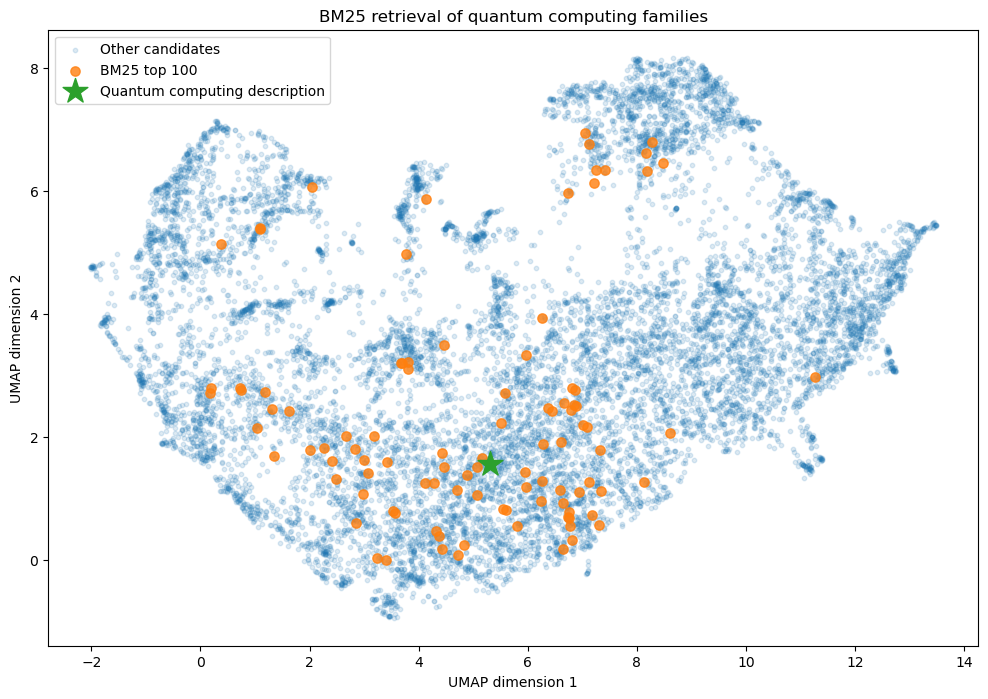

In [56]:
plot_retrieval_map(candidates, "in_bm25_top", f"BM25 top {k}", "BM25 retrieval of quantum computing families")

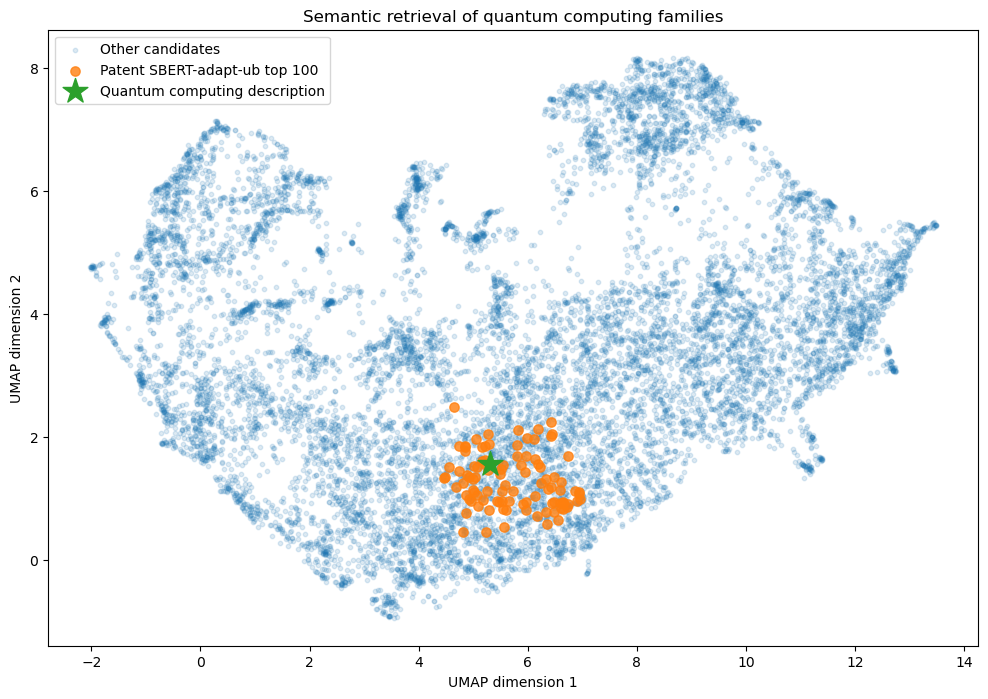

In [57]:
plot_retrieval_map(candidates, "in_sbert_top", f"Patent SBERT-adapt-ub top {k}", "Semantic retrieval of quantum computing families")

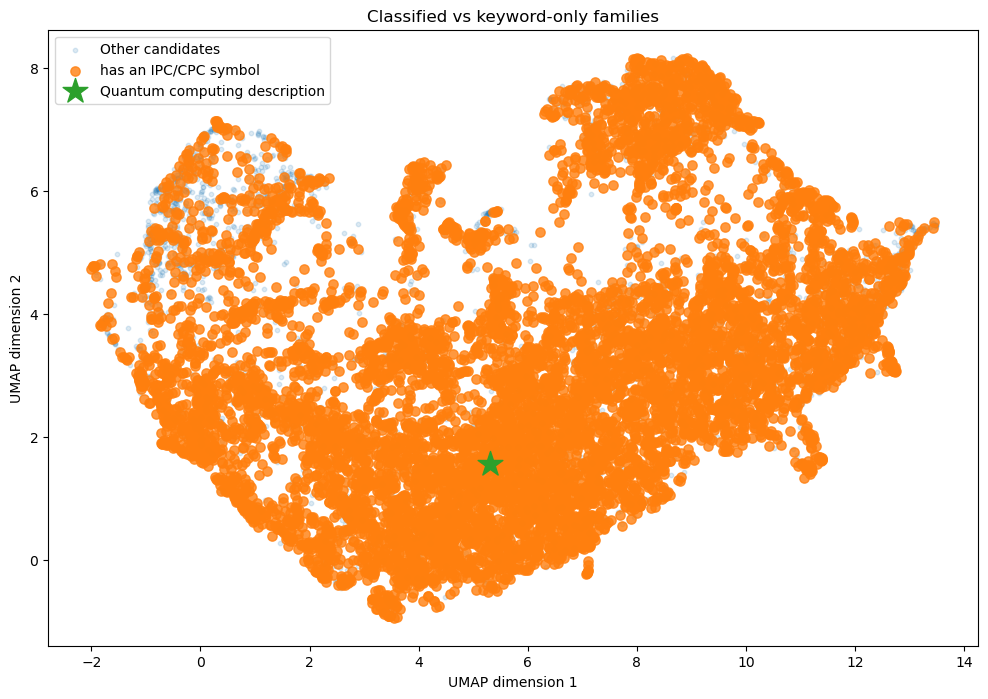

In [58]:
plot_retrieval_map(candidates, "has_class", "has an IPC/CPC symbol", "Classified vs keyword-only families")